In [1]:
from pathlib import Path

data_path = Path("../data/raw/telco_customer_churn.csv")

### 📂 Load Dataset Path

We define the **file path** for the Telco Customer Churn dataset using Python’s `pathlib`:

- `Path` provides an **object-oriented interface** for filesystem paths  
- `data_path` points to the raw dataset stored in the `../data/raw/` directory  
- This ensures portability across operating systems (Windows, macOS, Linux)  

The dataset file:  
**`telco_customer_churn.csv`**


In [3]:
data_path.exists()

True

### ✅ Dataset Path Verified

We confirmed that the dataset file exists at the specified location:

- `data_path.exists()` returned **True**  
- This means the file `telco_customer_churn.csv` is present in the `../data/raw/` directory  

In [4]:
import pandas as pd
df = pd.read_csv(data_path)

In [5]:
df.shape

(7043, 21)

### 📐 Dataset Dimensions

- **Number of rows:** 7043 (each row represents a customer record)  
- **Number of columns:** 21 (each column represents a feature/attribute)  


In [6]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

### 🏷️ Dataset Features

The Telco Customer Churn dataset contains **21 columns** (features):

- **customerID** → Unique identifier for each customer  
- **gender** → Male or Female  
- **SeniorCitizen** → Indicates if the customer is a senior (binary: 0/1)  
- **Partner** → Whether the customer has a partner (Yes/No)  
- **Dependents** → Whether the customer has dependents (Yes/No)  
- **tenure** → Number of months the customer has stayed with the company  
- **PhoneService** → Availability of phone service (Yes/No)  
- **MultipleLines** → Multiple phone lines (Yes/No/No phone service)  
- **InternetService** → Type of internet service (DSL/Fiber optic/No)  
- **OnlineSecurity**, **OnlineBackup**, **DeviceProtection**, **TechSupport** → Availability of additional services (Yes/No/No internet service)  
- **StreamingTV**, **StreamingMovies** → Streaming services subscribed (Yes/No/No internet service)  
- **Contract** → Type of contract (Month-to-month/One year/Two year)  
- **PaperlessBilling** → Billing preference (Yes/No)  
- **PaymentMethod** → Payment type (Electronic check, Mailed check, Bank transfer, Credit card)  
- **MonthlyCharges** → Monthly billing amount  
- **TotalCharges** → Total amount charged  
- **Churn** → Target variable (Yes/No) indicating if the customer left the company  



In [7]:
df["Churn"].head()

0     No
1     No
2    Yes
3     No
4    Yes
Name: Churn, dtype: object

In [8]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

### 🎯 Target Variable: Churn Distribution

The dataset shows the following churn breakdown:

- **No (customers retained):** 5174  
- **Yes (customers churned):** 1869  

This indicates that about **26.5% of customers have churned**, while **73.5% have stayed**.  
The dataset is therefore **imbalanced**, with more "No" cases than "Yes" cases.  

In [9]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### 🧾 Dataset Structure and Data Types

The Telco Customer Churn dataset contains **7043 entries** and **21 columns**.  
Key observations from `df.info()`:

- **Identifiers & categorical features:**  
  - `customerID` (object) → unique customer identifier  
  - Most service-related variables (`gender`, `Partner`, `Dependents`, `PhoneService`, etc.) are stored as `object` (string categories)  

- **Numeric features:**  
  - `SeniorCitizen` (int64) → binary indicator (0 = No, 1 = Yes)  
  - `tenure` (int64) → number of months with the company  
  - `MonthlyCharges` (float64) → monthly billing amount  

- **Potential data quality issue:**  
  - `TotalCharges` is stored as `object` instead of numeric. This suggests some non-numeric values (e.g., blanks or spaces) that need cleaning before analysis.  

- **Target variable:**  
  - `Churn` (object) → categorical (Yes/No)  


In [12]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].dtypes

tenure              int64
MonthlyCharges    float64
TotalCharges       object
dtype: object

In [13]:
df["TotalCharges"].head(10)

0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: object

In [15]:
df["TotalCharges"].count()

np.int64(7043)

In [14]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [16]:
df["TotalCharges"].str.strip().eq("").sum()

np.int64(11)

In [17]:
blank_mask = df["TotalCharges"].str.strip().eq("")

df.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [18]:
df.loc[blank_mask, "tenure"].value_counts()

tenure
0    11
Name: count, dtype: int64

### 🔎 Data Quality Check: `TotalCharges`

- The dataset contains **7,043 customer records**.  
- The column **`TotalCharges`** is stored as `object` instead of numeric.  
- There are **11 entries** with blank or whitespace-only values.  
- All 11 customers have **`tenure = 0`**, meaning they are new customers with no billing history.  
- These blanks are not automatically recognized as missing values (`NaN`) by Pandas.  
- No data has been modified or removed at this stage.

**Decision:**  
Defer treatment of these values until the **preprocessing stage**, after further investigation.  
Possible approaches include:
- Converting `TotalCharges` to numeric with `pd.to_numeric(errors="coerce")`  
- Handling blanks as missing values (`NaN`) and imputing or dropping them  
- Aligning treatment with business rules (e.g., setting `TotalCharges = 0` for tenure = 0)


In [19]:
df.select_dtypes(include="number").columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges'], dtype='object')

In [20]:
df.select_dtypes(include="object").columns

Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges',
       'Churn'],
      dtype='object')

In [21]:
df.nunique()

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

In [22]:
df["tenure"].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

In [25]:
%pip install matplotlib

  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ----------------------------- ---------- 1.8/2.5 MB 12.6 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 11.0 MB/s  0:00:00
Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl (70 kB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)

   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------------------- 0/6 [pyparsing]



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
import matplotlib.pyplot as plt

<Axes: >

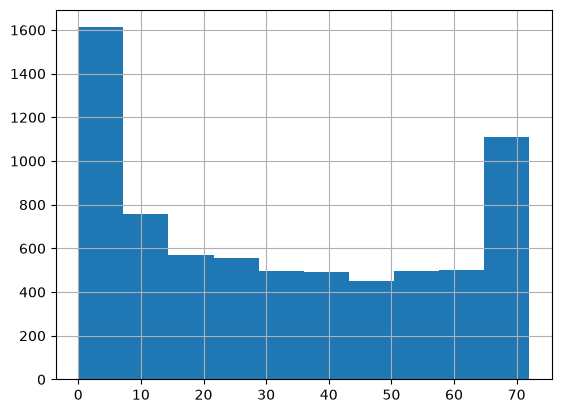

In [27]:
df["tenure"].hist()

In [28]:
df["MonthlyCharges"].describe()

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64

In [29]:
df["TotalCharges"].describe()

count     7043
unique    6531
top       20.2
freq        11
Name: TotalCharges, dtype: object

In [30]:
df["TotalCharges"].value_counts().head(10)

TotalCharges
20.2     11
         11
19.75     9
19.65     8
19.9      8
20.05     8
19.55     7
45.3      7
19.45     6
20.25     6
Name: count, dtype: int64

In [31]:
df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [32]:
df["Contract"].value_counts(normalize=True) * 100

Contract
Month-to-month    55.019168
Two year          24.066449
One year          20.914383
Name: proportion, dtype: float64

In [33]:
df.groupby("Contract")["Churn"].value_counts()

Contract        Churn
Month-to-month  No       2220
                Yes      1655
One year        No       1307
                Yes       166
Two year        No       1647
                Yes        48
Name: count, dtype: int64

In [34]:
df.groupby("Contract")["Churn"].value_counts(normalize=True) * 100

Contract        Churn
Month-to-month  No       57.290323
                Yes      42.709677
One year        No       88.730482
                Yes      11.269518
Two year        No       97.168142
                Yes       2.831858
Name: proportion, dtype: float64

### 📑 Contract Type and Customer Churn

The churn rate differs substantially across contract types:

- **Month-to-month:** 42.71%  
- **One year:** 11.27%  
- **Two year:** 2.83%  

#### 🔎 Observation
- Customers with **month-to-month contracts** have the highest churn rate.  
- Customers with **two-year contracts** show the lowest churn rate.  

#### 📈 Interpretation
Contract type appears to be **strongly associated with churn**.  
This relationship is worth investigating further during **feature analysis** and **model development**.

#### ⚠️ Limitation
This observation does **not establish causation**.  
Contract type may correlate with churn, but other factors (e.g., customer demographics, service quality, or payment method) could also influence this relationship.


In [35]:
df["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [36]:
df.groupby("PaymentMethod")["Churn"].value_counts()

PaymentMethod              Churn
Bank transfer (automatic)  No       1286
                           Yes       258
Credit card (automatic)    No       1290
                           Yes       232
Electronic check           No       1294
                           Yes      1071
Mailed check               No       1304
                           Yes       308
Name: count, dtype: int64

In [37]:
df.groupby("PaymentMethod")["Churn"].value_counts(normalize=True) * 100

PaymentMethod              Churn
Bank transfer (automatic)  No       83.290155
                           Yes      16.709845
Credit card (automatic)    No       84.756899
                           Yes      15.243101
Electronic check           No       54.714588
                           Yes      45.285412
Mailed check               No       80.893300
                           Yes      19.106700
Name: proportion, dtype: float64

### 💳 Payment Method and Customer Churn

The observed churn rates differ across payment methods:

- **Electronic check:** 45.29%  
- **Mailed check:** 19.11%  
- **Bank transfer (automatic):** 16.71%  
- **Credit card (automatic):** 15.24%  

#### 🔎 Observation
- Customers paying via **electronic check** have the highest churn rate.  
- Customers using **automatic credit card payments** have the lowest churn rate.  

#### 📈 Interpretation
Payment method appears to be **associated with churn** and may serve as a **predictive feature** in modeling.  
This suggests that **automatic payment methods** could be linked to stronger customer retention.

#### ⚠️ Limitation
This comparison does **not establish causation**.  
Other variables — such as **contract type** and **tenure** — may help explain the observed differences.


In [38]:
df.groupby("Churn")["MonthlyCharges"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


C:\Users\ANEES\AppData\Local\Temp\ipykernel_23628\582918415.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


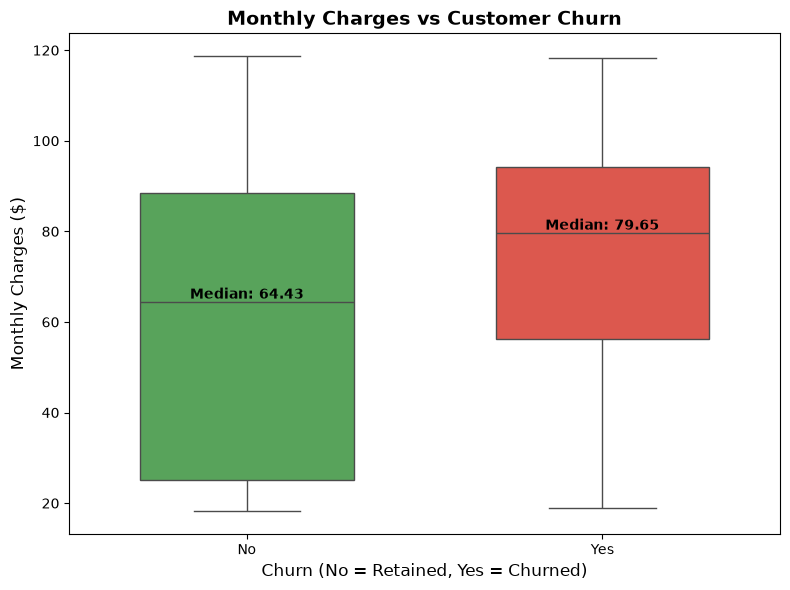

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))

ax = sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    palette=["#4CAF50", "#F44336"],  # green for No, red for Yes
    width=0.6
)

plt.title("Monthly Charges vs Customer Churn", fontsize=14, fontweight="bold")
plt.xlabel("Churn (No = Retained, Yes = Churned)", fontsize=12)
plt.ylabel("Monthly Charges ($)", fontsize=12)

# Add median labels
medians = df.groupby("Churn")["MonthlyCharges"].median()
for i, median in enumerate(medians):
    ax.text(
        i, median,
        f"Median: {median:.2f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="black"
    )

plt.tight_layout()
plt.show()


### 💰 Monthly Charges and Customer Churn

- **Mean monthly charges (No churn):** 61.27  
- **Mean monthly charges (Yes churn):** 74.44  
- **Median monthly charges (No churn):** 64.43  
- **Median monthly charges (Yes churn):** 79.65  

#### 🔎 Observation
Customers who churned tend to have **higher mean and median monthly charges** compared to those who stayed.

#### 📊 Visualization
The box plot shows:
- A **higher median** for the churned group  
- Noticeable overlap in distributions, meaning monthly charges alone do not perfectly separate the two groups  

#### 📈 Interpretation
Monthly charges are **associated with churn** — higher charges may increase the likelihood of churn.  
This feature could be useful in predictive modeling, especially when combined with other variables.

#### ⚠️ Limitation
This association does **not establish causation**.  
Monthly charges alone cannot fully distinguish churners from non‑churners, and other factors (e.g., contract type, tenure, payment method) may explain the observed differences.


In [40]:
df.groupby("Churn")["tenure"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


C:\Users\ANEES\AppData\Local\Temp\ipykernel_23628\3810499134.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


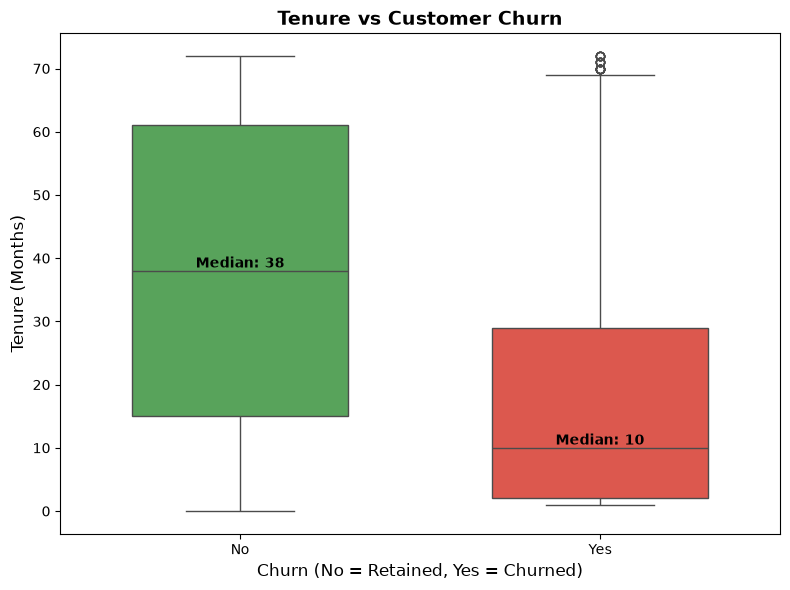

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))

ax = sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    palette=["#4CAF50", "#F44336"],  # green for No, red for Yes
    width=0.6
)

plt.title("Tenure vs Customer Churn", fontsize=14, fontweight="bold")
plt.xlabel("Churn (No = Retained, Yes = Churned)", fontsize=12)
plt.ylabel("Tenure (Months)", fontsize=12)

# Add median labels
medians = df.groupby("Churn")["tenure"].median()
for i, median in enumerate(medians):
    ax.text(
        i, median,
        f"Median: {median:.0f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="black"
    )

plt.tight_layout()
plt.show()


### ⏳ Tenure and Customer Churn

- **Mean tenure (No churn):** 37.57 months  
- **Mean tenure (Yes churn):** 17.98 months  
- **Median tenure (No churn):** 38 months  
- **Median tenure (Yes churn):** 10 months  

#### 🔎 Observation
Customers who churned generally had **shorter tenure** compared to those who stayed.  
This suggests that **longer customer relationships** are linked to stronger retention.

#### 📊 Visualization
The box plot shows:
- A **substantial difference in median tenure** between churned and retained groups  
- Some long-tenure customers still churned, highlighting exceptions  

#### 📈 Interpretation
Tenure is **associated with churn** in this dataset and is likely to be a **strong predictive feature**.  
It reflects customer loyalty and engagement over time.

#### ⚠️ Limitation
This comparison does **not establish causation**.  
Tenure alone cannot perfectly predict churn, and other factors (e.g., contract type, payment method, monthly charges) may also influence outcomes.


In [47]:
df["InternetService"].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [48]:
df.groupby("InternetService")["Churn"].value_counts()

InternetService  Churn
DSL              No       1962
                 Yes       459
Fiber optic      No       1799
                 Yes      1297
No               No       1413
                 Yes       113
Name: count, dtype: int64

In [49]:
df.groupby("InternetService")["Churn"].value_counts(normalize=True)*100

InternetService  Churn
DSL              No       81.040892
                 Yes      18.959108
Fiber optic      No       58.107235
                 Yes      41.892765
No               No       92.595020
                 Yes       7.404980
Name: proportion, dtype: float64

### 🌐 Internet Service and Customer Churn

Observed churn rates by internet service type:

- **Fiber optic:** 41.89%  
- **DSL:** 18.96%  
- **No internet service:** 7.40%  

#### 🔎 Observation
- Customers with **fiber optic service** have the highest churn rate.  
- Customers without internet service show the lowest churn rate.  

#### 📈 Interpretation
Internet service type appears to be **associated with churn** and may serve as a **predictive feature**.  
This suggests that service quality or cost differences across internet types could influence customer retention.

#### ⚠️ Limitation
This comparison does **not establish causation**.  
Other variables — such as **contract type, tenure, monthly charges, and demographics** — may contribute to the observed pattern.


In [50]:
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

In [51]:
total_charges_numeric.isna().sum()

np.int64(11)

In [52]:
df.loc[
    total_charges_numeric.isna(),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [53]:
df.loc[
    total_charges_numeric.isna(),
    "Churn"
].value_counts()

Churn
No    11
Name: count, dtype: int64

In [54]:
total_charges_numeric.describe()

count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64

In [55]:
df.groupby("Churn")["customerID"].count()

Churn
No     5174
Yes    1869
Name: customerID, dtype: int64

In [56]:
df.groupby("Churn")["tenure"].mean()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

In [57]:
df.groupby("Churn").apply(
    lambda group: total_charges_numeric.loc[group.index].mean()
)

C:\Users\ANEES\AppData\Local\Temp\ipykernel_23628\469369703.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby("Churn").apply(


Churn
No     2555.344141
Yes    1531.796094
dtype: float64

In [58]:
total_charges_analysis = pd.DataFrame({
    "Churn": df["Churn"],
    "TotalCharges": total_charges_numeric
})

total_charges_analysis.groupby("Churn")["TotalCharges"].mean()

Churn
No     2555.344141
Yes    1531.796094
Name: TotalCharges, dtype: float64

In [59]:
total_charges_analysis.groupby("Churn")["TotalCharges"].median()

Churn
No     1683.60
Yes     703.55
Name: TotalCharges, dtype: float64


### Objective
Investigate the `TotalCharges` column to understand its data quality, numerical distribution, and relationship with customer churn.

### 1. Data Quality Findings
- The dataset contains **7,043 records**.
- The original `TotalCharges` column was stored as an object (string) data type rather than a numeric type.
- We identified **11 blank or whitespace-only values**.
- After converting the column to numeric using `pd.to_numeric()` with `errors="coerce"`, these 11 values became `NaN`.
- All 11 affected customers had `tenure = 0`, positive `MonthlyCharges`, and `Churn = No`.
- A separate numeric series, `total_charges_numeric`, was created for analysis. The original DataFrame was not modified.

### 2. Numerical Summary

| Statistic | Value |
|---|---:|
| Valid numeric values | 7,032 |
| Mean | 2,283.30 |
| Standard deviation | 2,266.77 |
| Minimum | 18.80 |
| 25th percentile | 401.45 |
| Median | 1,397.48 |
| 75th percentile | 3,794.74 |
| Maximum | 8,684.80 |

The mean is higher than the median, suggesting that the distribution may be right-skewed.

### 3. Total Charges by Churn Status

| Statistic | Stayed (`No`) | Churned (`Yes`) |
|---|---:|---:|
| Mean total charges | 2,555.34 | 1,531.80 |
| Median total charges | 1,683.60 | 703.55 |

Customers who stayed had higher mean and median total charges than customers who churned.

### 4. Key Insights
1. The `TotalCharges` column requires attention because it contains 11 blank values and was initially stored as text.
2. Customers with blank total charges all had zero recorded tenure and were labelled `Churn = No`.
3. Both the mean and median total charges were lower among customers who churned.
4. These differences may partly reflect the shorter tenure of customers who churned, since total charges accumulate over time.
5. The observed relationships do not establish causation.

### 5. Next Steps
- Decide how to handle the 11 missing numeric values during data preparation.
- Continue exploring relationships between customer characteristics and churn.
- Preserve the original raw dataset and perform any cleaning on a separate copy or through a reproducible preprocessing pipeline.

In [62]:
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

In [63]:
df.groupby("Churn")["MonthlyCharges"].median()

Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64

C:\Users\ANEES\AppData\Local\Temp\ipykernel_23628\403587044.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


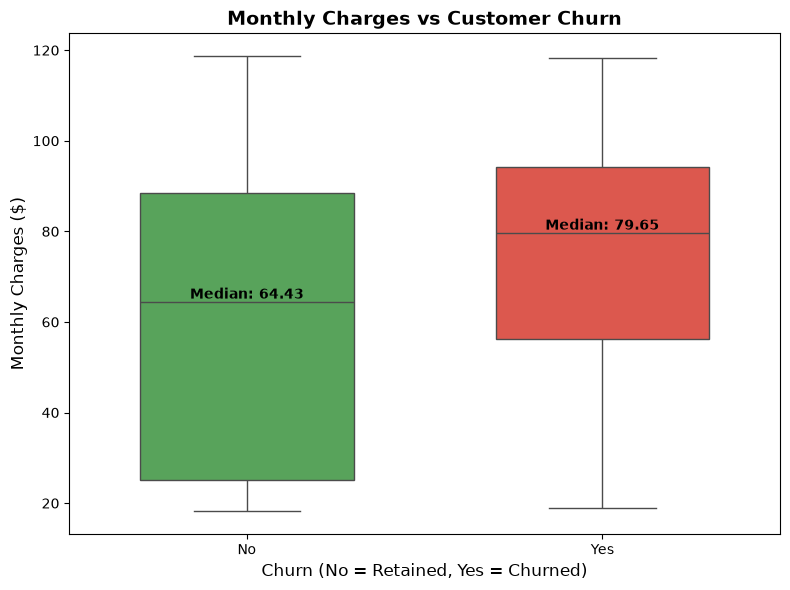

In [64]:
plt.figure(figsize=(8,6))

ax = sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    palette=["#4CAF50", "#F44336"],  # green for No, red for Yes
    width=0.6
)

plt.title("Monthly Charges vs Customer Churn", fontsize=14, fontweight="bold")
plt.xlabel("Churn (No = Retained, Yes = Churned)", fontsize=12)
plt.ylabel("Monthly Charges ($)", fontsize=12)

# Add median labels
medians = df.groupby("Churn")["MonthlyCharges"].median()
for i, median in enumerate(medians):
    ax.text(
        i, median,
        f"Median: {median:.2f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="black"
    )

plt.tight_layout()
plt.show()


### 📊 Visualizing Monthly Charges by Churn

#### Boxplot
- The boxplot compares **monthly charges** for churned vs retained customers.  
- Customers who churned generally have **higher monthly charges**, with a median about **15 units higher** than those who stayed.  
- Both groups show considerable variation, and the distributions overlap, meaning monthly charges alone cannot perfectly separate churned from retained customers.  

#### Key Takeaway
- **Higher monthly charges** are associated with churn in this dataset.  
- This feature may be useful in predictive modeling, especially when combined with other variables like **contract type, tenure, and payment method**.  
- However, the relationship is **correlational, not causal**, so further analysis is needed to confirm its predictive strength.


In [65]:
df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [66]:
df.groupby("Contract")["Churn"].value_counts()

Contract        Churn
Month-to-month  No       2220
                Yes      1655
One year        No       1307
                Yes       166
Two year        No       1647
                Yes        48
Name: count, dtype: int64

In [67]:
df.groupby("Contract")["Churn"].value_counts(normalize=True)*100

Contract        Churn
Month-to-month  No       57.290323
                Yes      42.709677
One year        No       88.730482
                Yes      11.269518
Two year        No       97.168142
                Yes       2.831858
Name: proportion, dtype: float64

C:\Users\ANEES\AppData\Local\Temp\ipykernel_23628\1710032222.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


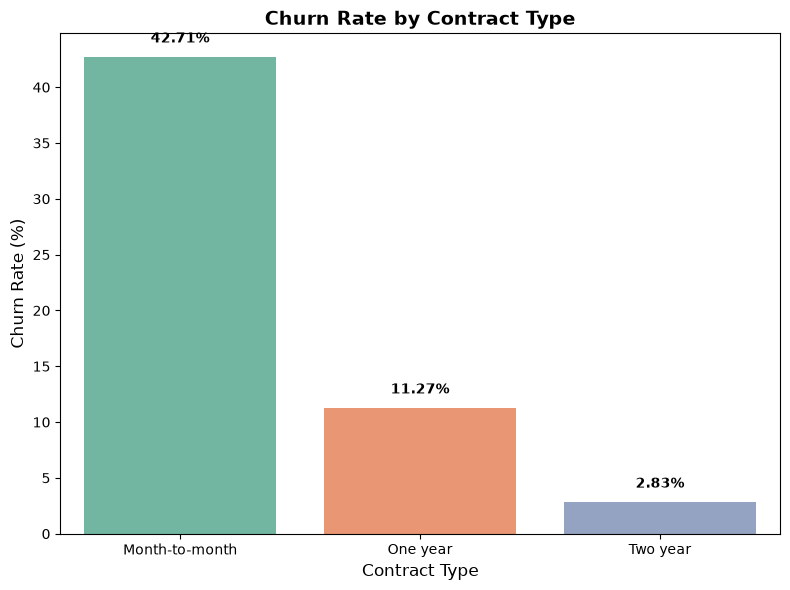

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate churn rate by contract type
contract_churn_rate = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8,6))

# Create barplot with Seaborn
ax = sns.barplot(
    x=contract_churn_rate.index,
    y=contract_churn_rate.values,
    palette="Set2"
)

# Add title and labels
plt.title("Churn Rate by Contract Type", fontsize=14, fontweight="bold")
plt.xlabel("Contract Type", fontsize=12)
plt.ylabel("Churn Rate (%)", fontsize=12)

# Annotate bars with exact percentages
for i, rate in enumerate(contract_churn_rate.values):
    ax.text(
        i, rate + 1,  # position slightly above bar
        f"{rate:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="black"
    )

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



Investigate the relationship between contract type and customer churn.

### 1. Contract Distribution

| Contract Type | Customer Count | Percentage |
|---|---:|---:|
| Month-to-month | 3,875 | 55.02% |
| One year | 1,473 | 20.91% |
| Two year | 1,695 | 24.07% |
| **Total** | **7,043** | **100%** |

Month-to-month contracts represent the largest customer group.

### 2. Churn Rate by Contract Type

| Contract Type | Churned Customers | Churn Rate |
|---|---:|---:|
| Month-to-month | 1,655 | 42.71% |
| One year | 166 | 11.27% |
| Two year | 48 | 2.83% |

### 3. Visualization
A bar chart was created to compare churn rates across contract types.

### 4. Key Insights
1. Month-to-month customers have the highest observed churn rate.
2. Two-year contract customers have the lowest observed churn rate.
3. Churn rates decrease across the one-year and two-year contract categories compared with month-to-month contracts.
4. Contract type may be an informative feature for customer churn prediction.

### 5. Conclusion
Contract type is strongly associated with customer churn in this dataset. However, the analysis does not establish causation, and other customer characteristics may also contribute to the observed differences.

In [70]:
df["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [72]:
df["OnlineSecurity"].value_counts()

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

In [73]:
df.groupby("OnlineSecurity")["Churn"].value_counts()

OnlineSecurity       Churn
No                   No       2037
                     Yes      1461
No internet service  No       1413
                     Yes       113
Yes                  No       1724
                     Yes       295
Name: count, dtype: int64

In [74]:
df.groupby("OnlineSecurity")["Churn"].value_counts(normalize=True)*100

OnlineSecurity       Churn
No                   No       58.233276
                     Yes      41.766724
No internet service  No       92.595020
                     Yes       7.404980
Yes                  No       85.388806
                     Yes      14.611194
Name: proportion, dtype: float64

## Online Security Analysis

### Objective
Investigate the relationship between online security service and customer churn.

### 1. Customer Distribution

| OnlineSecurity | Customer Count |
|---|---:|
| No | 3,498 |
| Yes | 2,019 |
| No internet service | 1,526 |

### 2. Churn Rate by Category

| OnlineSecurity | Churned Customers | Churn Rate |
|---|---:|---:|
| No | 1,461 | 41.77% |
| Yes | 295 | 14.61% |
| No internet service | 113 | 7.40% |

### 3. Key Insights
1. Customers without online security have the highest observed churn rate.
2. Customers with online security have a lower observed churn rate than customers without it.
3. Customers without internet service have the lowest observed churn rate among these categories.
4. OnlineSecurity may provide useful information for customer churn prediction.

### 4. Conclusion
OnlineSecurity is associated with customer churn in this dataset. This descriptive analysis does not establish causation, and the relationship may be influenced by other customer characteristics.

In [75]:
df["TechSupport"].value_counts()

TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

In [76]:
df.groupby("TechSupport")["Churn"].value_counts()

TechSupport          Churn
No                   No       2027
                     Yes      1446
No internet service  No       1413
                     Yes       113
Yes                  No       1734
                     Yes       310
Name: count, dtype: int64

In [77]:
df.groupby("TechSupport")["Churn"].value_counts(normalize=True)*100


TechSupport          Churn
No                   No       58.364526
                     Yes      41.635474
No internet service  No       92.595020
                     Yes       7.404980
Yes                  No       84.833659
                     Yes      15.166341
Name: proportion, dtype: float64

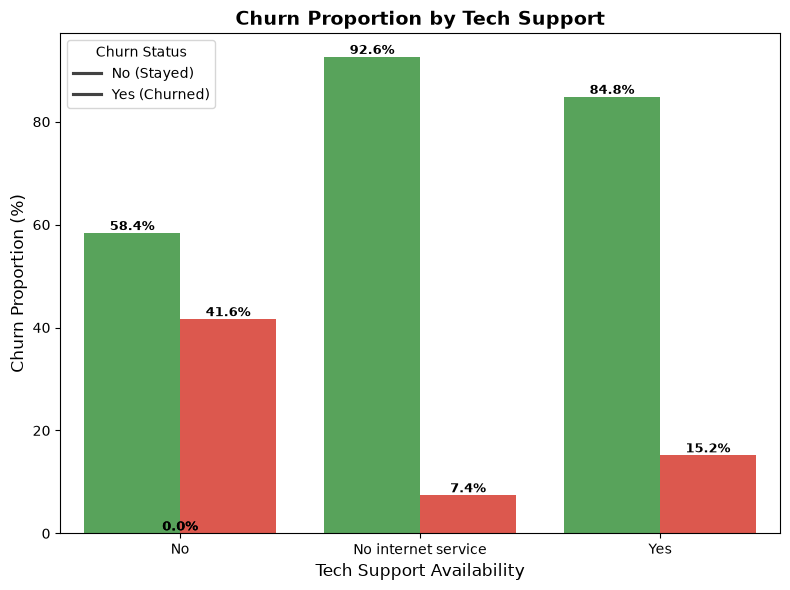

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate churn proportions by TechSupport
tech_churn = (
    df.groupby("TechSupport")["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("proportion")
    .reset_index()
)

plt.figure(figsize=(8,6))

ax = sns.barplot(
    data=tech_churn,
    x="TechSupport",
    y="proportion",
    hue="Churn",
    palette=["#4CAF50", "#F44336"]  # green for No, red for Yes
)

plt.title("Churn Proportion by Tech Support", fontsize=14, fontweight="bold")
plt.xlabel("Tech Support Availability", fontsize=12)
plt.ylabel("Churn Proportion (%)", fontsize=12)
plt.legend(title="Churn Status", labels=["No (Stayed)", "Yes (Churned)"])

# Annotate bars with percentages
for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.1f}%",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center", va="bottom",
        fontsize=9, fontweight="bold"
    )

plt.tight_layout()
plt.show()


## Tech Support Analysis

### Objective
Investigate the relationship between technical support service and customer churn.

### 1. Customer Distribution

| TechSupport | Customer Count |
|---|---:|
| No | 3,473 |
| Yes | 2,044 |
| No internet service | 1,526 |

### 2. Churn Rate by Category

| TechSupport | Churned Customers | Churn Rate |
|---|---:|---:|
| No | 1,446 | 41.64% |
| Yes | 310 | 15.17% |
| No internet service | 113 | 7.40% |

### 3. Key Insights
1. Customers without technical support have the highest observed churn rate.
2. Customers with technical support have a lower observed churn rate.
3. Customers without internet service have the lowest observed churn rate among these categories.
4. TechSupport may provide useful information for customer churn prediction.

### 4. Conclusion
TechSupport is associated with customer churn in this dataset. This analysis does not establish causation, and the relationship may overlap with other features, including OnlineSecurity and InternetService.

In [79]:
df["OnlineBackup"].value_counts()

OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

In [80]:
df.groupby("OnlineBackup")["Churn"].value_counts()

OnlineBackup         Churn
No                   No       1855
                     Yes      1233
No internet service  No       1413
                     Yes       113
Yes                  No       1906
                     Yes       523
Name: count, dtype: int64

In [81]:
df.groupby("OnlineBackup")["Churn"].value_counts(normalize=True)*100


OnlineBackup         Churn
No                   No       60.071244
                     Yes      39.928756
No internet service  No       92.595020
                     Yes       7.404980
Yes                  No       78.468506
                     Yes      21.531494
Name: proportion, dtype: float64

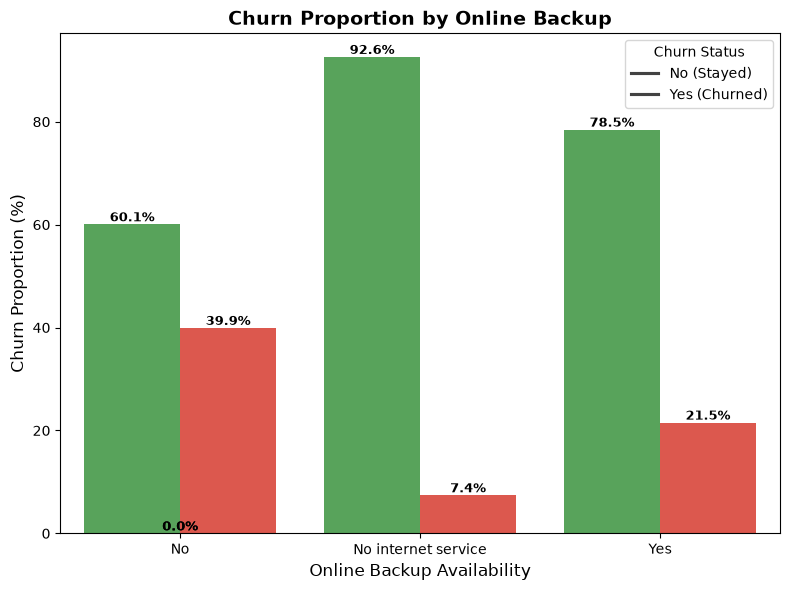

In [83]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate churn proportions by OnlineBackup
online_churn = (
    df.groupby("OnlineBackup")["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("proportion")
    .reset_index()
)

plt.figure(figsize=(8,6))

ax = sns.barplot(
    data=online_churn,
    x="OnlineBackup",
    y="proportion",
    hue="Churn",
    palette=["#4CAF50", "#F44336"]  # green for No, red for Yes
)

plt.title("Churn Proportion by Online Backup", fontsize=14, fontweight="bold")
plt.xlabel("Online Backup Availability", fontsize=12)
plt.ylabel("Churn Proportion (%)", fontsize=12)
plt.legend(title="Churn Status", labels=["No (Stayed)", "Yes (Churned)"])

# Annotate bars with percentages
for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.1f}%",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center", va="bottom",
        fontsize=9, fontweight="bold"
    )

plt.tight_layout()
plt.show()


##  Online Backup Analysis

### Objective
Investigate the relationship between online backup service and customer churn.

### 1. Churn Rate by Category

| OnlineBackup | Customer Count | Churned Customers | Churn Rate |
|---|---:|---:|---:|
| No | 3,088 | 1,233 | 39.93% |
| Yes | 2,429 | 523 | 21.53% |
| No internet service | 1,526 | 113 | 7.40% |

### 2. Key Insights
1. Customers without online backup have a higher observed churn rate than customers with online backup.
2. The churn-rate difference between customers without and with online backup is approximately 18.40 percentage points.
3. Customers without internet service have the lowest observed churn rate among these categories.
4. OnlineBackup may be a useful feature for customer churn prediction.

### 3. Conclusion
OnlineBackup is associated with customer churn in this dataset. The analysis does not establish causation, and the observed relationship may overlap with other customer characteristics and service choices.

In [85]:
df["DeviceProtection"].value_counts()

DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

In [86]:
df.groupby("DeviceProtection")["Churn"].value_counts()

DeviceProtection     Churn
No                   No       1884
                     Yes      1211
No internet service  No       1413
                     Yes       113
Yes                  No       1877
                     Yes       545
Name: count, dtype: int64

In [87]:
df.groupby("DeviceProtection")["Churn"].value_counts(normalize=True)*100

DeviceProtection     Churn
No                   No       60.872375
                     Yes      39.127625
No internet service  No       92.595020
                     Yes       7.404980
Yes                  No       77.497936
                     Yes      22.502064
Name: proportion, dtype: float64

## Device Protection Analysis

### Objective
Investigate the relationship between device protection service and customer churn.

### 1. Churn Rate by Category

| DeviceProtection | Churn Rate |
|---|---:|
| No | 39.13% |
| Yes | 22.50% |
| No internet service | 7.40% |

### 2. Key Insights
1. Customers without device protection have a higher observed churn rate than customers with device protection.
2. The difference between these two churn rates is approximately 16.63 percentage points.
3. Customers without internet service have the lowest observed churn rate among these categories.
4. DeviceProtection may provide useful information for predicting customer churn.

### 3. Conclusion
DeviceProtection is associated with customer churn in this dataset. This descriptive analysis does not establish causation, and the observed relationship may overlap with other customer characteristics and service choices.

In [88]:
df.groupby("StreamingTV")["Churn"].value_counts(normalize=True).mul(100)

StreamingTV          Churn
No                   No       66.476868
                     Yes      33.523132
No internet service  No       92.595020
                     Yes       7.404980
Yes                  No       69.929812
                     Yes      30.070188
Name: proportion, dtype: float64

## Streaming TV Analysis

### Objective
Investigate the relationship between StreamingTV service and customer churn.

### 1. Churn Rate by Category

| StreamingTV | Churn Rate | Retention Rate |
|---|---:|---:|
| No | 33.52% | 66.48% |
| Yes | 30.07% | 69.93% |
| No internet service | 7.40% | 92.60% |

### 2. Key Insights
1. Customers without StreamingTV have a slightly higher observed churn rate than customers with StreamingTV.
2. The difference between these two churn rates is approximately 3.45 percentage points.
3. Customers without internet service have the lowest observed churn rate among these categories.
4. StreamingTV may be less informative on its own than some other features explored so far, although its predictive value must be evaluated during model development.

### 3. Conclusion
StreamingTV shows a relatively small difference in churn rates between customers with and without the service. This descriptive analysis does not establish causation.

In [89]:
df.groupby("StreamingMovies")["Churn"].value_counts(normalize=True).mul(100)

StreamingMovies      Churn
No                   No       66.319569
                     Yes      33.680431
No internet service  No       92.595020
                     Yes       7.404980
Yes                  No       70.058565
                     Yes      29.941435
Name: proportion, dtype: float64

## Streaming Movies Analysis

### Objective
Investigate the relationship between StreamingMovies service and customer churn.

### 1. Churn Rate by Category

| StreamingMovies | Churn Rate | Retention Rate |
|---|---:|---:|
| No | 33.68% | 66.32% |
| Yes | 29.94% | 70.06% |
| No internet service | 7.40% | 92.60% |

### 2. Key Insights
1. Customers without StreamingMovies have a slightly higher observed churn rate than customers with the service.
2. The difference between these two churn rates is approximately 3.74 percentage points.
3. Customers without internet service have the lowest observed churn rate among these categories.
4. StreamingMovies may offer some predictive information, but its value should be evaluated alongside other features.

### 3. Conclusion
StreamingMovies shows a relatively small difference in churn rates between customers with and without the service. This descriptive analysis does not establish causation.

In [91]:
rem_features=[
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "PaperlessBilling"
]

In [95]:
for feature in rem_features:
    print("="*60)
    print(df.groupby(feature)["Churn"].value_counts(normalize=True).mul(100))
    print("="*60)


gender  Churn
Female  No       73.079128
        Yes      26.920872
Male    No       73.839662
        Yes      26.160338
Name: proportion, dtype: float64
Partner  Churn
No       No       67.042021
         Yes      32.957979
Yes      No       80.335097
         Yes      19.664903
Name: proportion, dtype: float64
Dependents  Churn
No          No       68.720860
            Yes      31.279140
Yes         No       84.549763
            Yes      15.450237
Name: proportion, dtype: float64
PhoneService  Churn
No            No       75.073314
              Yes      24.926686
Yes           No       73.290363
              Yes      26.709637
Name: proportion, dtype: float64
MultipleLines     Churn
No                No       74.955752
                  Yes      25.044248
No phone service  No       75.073314
                  Yes      24.926686
Yes               No       71.390104
                  Yes      28.609896
Name: proportion, dtype: float64
PaperlessBilling  Churn
No                No  

## Customer Characteristics and Churn Analysis

### Objective
Investigate the relationship between gender, partner status, dependents, phone service, multiple lines, and paperless billing and customer churn.

### 1. Churn Rate by Category

| Feature | Category | Churn Rate |
|---|---|---:|
| Gender | Female | 26.92% |
| Gender | Male | 26.16% |
| Partner | No | 32.96% |
| Partner | Yes | 19.66% |
| Dependents | No | 31.28% |
| Dependents | Yes | 15.45% |
| PhoneService | No | 24.93% |
| PhoneService | Yes | 26.71% |
| MultipleLines | No | 25.04% |
| MultipleLines | No phone service | 24.93% |
| MultipleLines | Yes | 28.61% |
| PaperlessBilling | No | 16.33% |
| PaperlessBilling | Yes | 33.57% |

### 2. Key Insights
1. PaperlessBilling shows a substantial difference in observed churn rates between its categories.
2. Customers without a partner have a higher observed churn rate than customers with a partner.
3. Customers without dependents have a higher observed churn rate than customers with dependents.
4. Gender has relatively similar observed churn rates across its two categories.
5. PhoneService and MultipleLines show smaller differences in observed churn rates than some of the other features examined.

### 3. Conclusion
Customer characteristics and service choices show different levels of association with churn. These findings are useful for exploratory analysis but do not establish causation or determine a feature's predictive value on their own.

In [96]:
df.loc[
    blank_mask,
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


In [97]:
df["TotalCharges"].str.strip().eq("").sum()

np.int64(11)

In [98]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## Missing Value Assessment

### Findings
- `df.isna().sum()` returned zero missing values for every column in the original DataFrame.
- However, a separate inspection identified 11 blank or whitespace-only entries in `TotalCharges`.
- These blanks were not detected by `isna()` because they were stored as strings rather than recognized missing values.

### Conclusion
The dataset contains a data-quality issue that requires explicit handling during preprocessing. Missing-value checks should account for both recognized missing values and blank strings.

The original DataFrame remains unchanged.

In [99]:
df.duplicated().sum()

np.int64(0)

## Duplicate Record Assessment

### Objective
Check whether the dataset contains exact duplicate rows.

### Finding
The expression `df.duplicated().sum()` returned `0`.

### Conclusion
No exact duplicate rows were detected in the original dataset. Therefore, no duplicate-row removal is required based on this check.

Note that this check identifies exact duplicate rows; it does not establish whether every individual feature value is valid.

In [100]:
df.shape

(7043, 21)

##  Dataset Integrity Check

### Finding
The original DataFrame has a shape of `(7043, 21)`.

- **Rows:** 7,043 customer records
- **Columns:** 21 features and target/identifier columns

### Conclusion
The original dataset retains its expected dimensions after the exploratory analysis. No rows or columns have been removed during our investigation.

In [101]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

## Data Type Assessment

### Findings
- `customerID` is stored as an object and serves as a customer identifier.
- Most categorical features are stored as object columns.
- `SeniorCitizen` is an integer indicator with values representing categories.
- `tenure` is stored as an integer.
- `MonthlyCharges` is stored as a floating-point number.
- `TotalCharges` is stored as an object despite representing numeric charges.
- `Churn` is the target variable.

### Preprocessing Considerations
1. Convert `TotalCharges` to a numeric representation while handling blank values.
2. Encode categorical predictors using a suitable strategy.
3. Treat `SeniorCitizen` as a categorical indicator where appropriate.
4. Exclude `customerID` from the model's predictive features.
5. Preserve `Churn` as the target and encode it appropriately for model training.

### Conclusion
The dataset contains a mixture of numerical and categorical features. Data types and missing-value handling must be addressed before training machine-learning models.

## Exploratory Data Analysis — Final Summary

### Dataset Overview
- Total records: 7,043
- Total columns: 21
- Target variable: `Churn`
- Identifier: `customerID`
- Churn distribution: 5,174 customers stayed and 1,869 customers churned.

### Data Quality Findings
- No exact duplicate rows were detected.
- `df.isna().sum()` reported no pandas-recognized missing values in the original dataset.
- Eleven blank or whitespace-only entries were identified in `TotalCharges`.
- All 11 affected records had `tenure = 0` and `Churn = No`.
- `TotalCharges` is stored as an object despite representing numerical values.

### Important Observations
- Customers with month-to-month contracts had a higher observed churn rate than customers with one-year or two-year contracts.
- Customers who churned had shorter average tenure and higher average monthly charges than customers who stayed.
- Churn rates differed across several service and customer-characteristic categories, including OnlineSecurity, TechSupport, OnlineBackup, DeviceProtection, Partner, Dependents, and PaperlessBilling.

### Preprocessing Considerations
1. Convert `TotalCharges` to numeric and handle its 11 blank entries deliberately.
2. Exclude `customerID` from predictive features.
3. Prepare categorical features for machine learning.
4. Preserve the target variable and avoid data leakage during preprocessing.
5. Perform transformations on a separate working dataset rather than modifying the original raw data.

### Conclusion
The exploratory analysis identified several potentially useful features and a data-quality issue requiring attention. These findings will guide preprocessing and model experimentation. The observed relationships are descriptive and do not establish causation.

In [102]:
numerical_df = df[
    ["SeniorCitizen", "tenure", "MonthlyCharges"]
].copy()

numerical_df["TotalCharges"] = total_charges_numeric

numerical_df.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
0,0,1,29.85,29.85
1,0,34,56.95,1889.50
2,0,2,53.85,108.15
3,0,45,42.30,1840.75
4,0,2,70.70,151.65


In [103]:
correlation_matrix = numerical_df.corr()

correlation_matrix

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.000000,0.016567,0.220173,0.102411
tenure,0.016567,1.000000,0.247900,0.825880
MonthlyCharges,0.220173,0.247900,1.000000,0.651065
TotalCharges,0.102411,0.825880,0.651065,1.000000


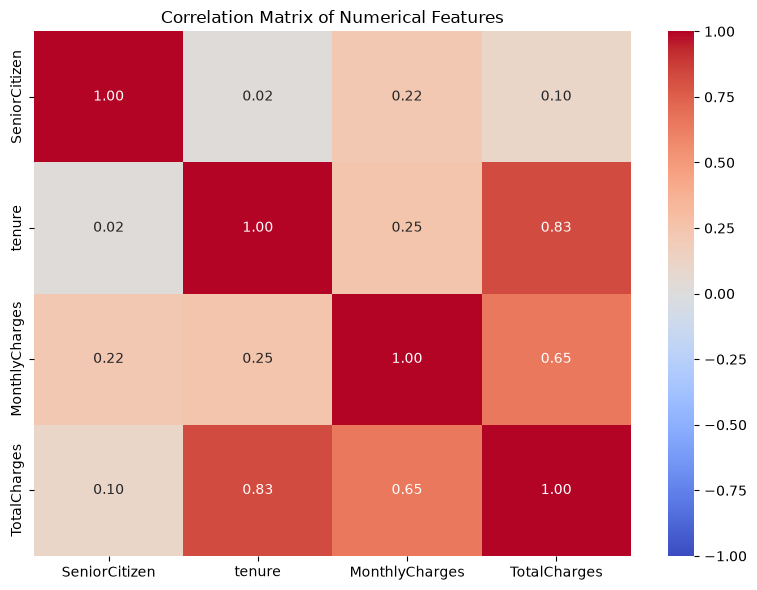

In [104]:

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

In [105]:
churn_numeric = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

churn_numeric.value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [106]:
numerical_churn_df = numerical_df.copy()

numerical_churn_df["Churn"] = churn_numeric

churn_correlation = numerical_churn_df.corr()["Churn"].drop("Churn")

churn_correlation.sort_values(ascending=False)

MonthlyCharges    0.193356
SeniorCitizen     0.150889
TotalCharges     -0.199484
tenure           -0.352229
Name: Churn, dtype: float64

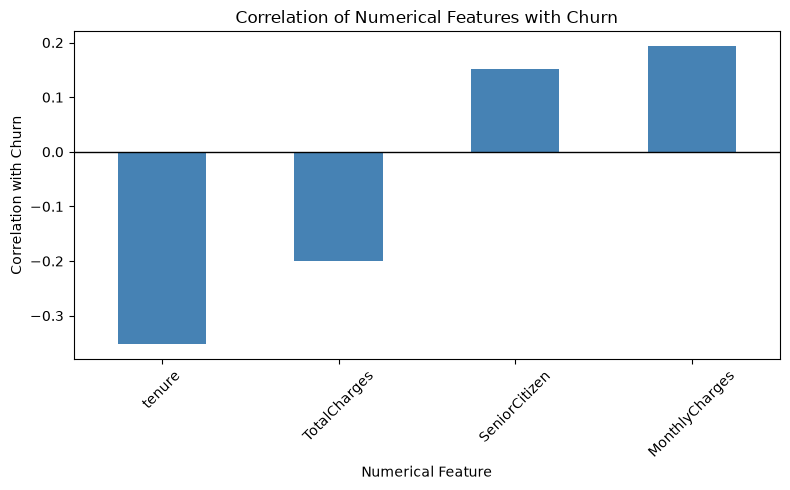

In [107]:
plt.figure(figsize=(8, 5))

churn_correlation.sort_values().plot(
    kind="bar",
    color="steelblue"
)

plt.axhline(y=0, color="black", linewidth=1)
plt.title("Correlation of Numerical Features with Churn")
plt.xlabel("Numerical Feature")
plt.ylabel("Correlation with Churn")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Numerical Feature Correlation Analysis

The correlation analysis examined relationships among numerical features and their associations with customer churn.

**Correlation between numerical features**
- `tenure` and `TotalCharges` showed a strong positive correlation of approximately **0.83**.
- `MonthlyCharges` and `TotalCharges` showed a positive correlation of approximately **0.65**.
- The remaining numerical feature pairs showed weak or negligible linear relationships.

**Correlation with churn**
- `tenure` had the strongest relationship with churn among the numerical features, with a correlation of approximately **−0.35**.
- `TotalCharges` had a weak negative correlation with churn of approximately **−0.20**.
- `MonthlyCharges` had a weak positive correlation with churn of approximately **0.19**.
- `SeniorCitizen` had a weak positive correlation with churn of approximately **0.15**.

**Interpretation:** Customers with longer tenure tended to have lower churn, while higher monthly charges and senior-citizen status were associated with slightly higher churn in this dataset. These correlations indicate associations, not causation.

**Limitation:** Pearson correlation measures linear relationships. The results do not capture all possible patterns and should be considered alongside the categorical churn-rate comparisons and subsequent model evaluation.